# Dataset Creation and Validation Workflow

This appendix notebook documents the project step where the DSSAT output files were parsed, cleaned, merged, and validated before modeling. It also preserves the modeling exploration that was performed at this stage of the project.

The main value of this notebook is reproducibility and traceability: it shows how the raw DSSAT `.OUT` files were converted into a validated tabular dataset and how that dataset was first tested for the 7-day GSTD 5 alert task.

During development, the validated merged file was saved as `capstone_secondary_dssat_merged_validated.csv`. For the final client handoff, the same validated dataset is provided under the standardized filename `final_validated_dataset.csv`.


# 1. DSSAT Output Parser

This section defines the parser used to read DSSAT `.OUT` files and convert them into pandas dataframes. The parser captures run number, treatment number, treatment name, and the tabular output rows from each DSSAT file.


In [1]:
import pandas as pd
import re
from pathlib import Path

def parse_dssat_outfile(filepath):
    filepath = Path(filepath)
    rows = []
    current_run = None
    current_trt = None
    current_trt_name = None
    current_cols = None

    with open(filepath, "r", encoding="utf-8", errors="ignore") as file:
        for raw_line in file:
            line = raw_line.rstrip("\n")

            # Capture run number
            if line.startswith("*RUN"):
                parts = line.split()
                if len(parts) >= 2:
                    current_run = parts[1]
                continue

            # Capture treatment number and name
            if line.strip().startswith("TREATMENT"):
                parts = line.split()
                if len(parts) >= 4:
                    current_trt = parts[1]
                    current_trt_name = parts[3]
                continue

            # Skip non-data lines
            if (
                line.strip() == ""
                or line.startswith("!")
                or line.startswith("*")
                or line.strip().startswith("DATA")
                or line.strip().startswith("MODEL")
                or line.strip().startswith("EXPERIMENT")
            ):
                continue

            # Header line
            if line.startswith("@"):
                current_cols = line[1:].split()
                continue

            # Data line
            if current_cols is not None and current_run is not None and current_trt is not None:
                parts = line.split()

                if len(parts) == len(current_cols):
                    row = dict(zip(current_cols, parts))
                    row["RUNNO"] = current_run
                    row["TRTNO"] = current_trt
                    row["TRTNA"] = current_trt_name
                    rows.append(row)

    df = pd.DataFrame(rows)

    # Convert numeric-looking columns where possible
    for col in df.columns:
        if col not in ["TRTNA"]:
            df[col] = pd.to_numeric(df[col], errors="ignore")

    return df


# 2. Parse and Audit Raw DSSAT Output Files

The following cells parse the four DSSAT output files used to build the modeling dataset: `PlantGro.OUT`, `Weather.OUT`, `SoilNi.OUT`, and `SoilWat.OUT`. After each parse, the notebook checks shape, run counts, treatment counts, year range, duplicate run-day rows, and available columns.


In [2]:
plantgro_df = parse_dssat_outfile("PlantGro.OUT")

print(plantgro_df.shape)
print(plantgro_df.head())
print("Unique runs:", plantgro_df["RUNNO"].nunique())
print("Unique treatments:", plantgro_df["TRTNO"].nunique())
print(plantgro_df.columns.tolist())


C:\Users\jacob\AppData\Local\Temp\ipykernel_13376\2587087079.py:64: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df[col] = pd.to_numeric(df[col], errors="ignore")


(135240, 52)
   YEAR  DOY  DAS  DAP  L#SD  GSTD  LAID  LWAD  SWAD  GWAD  ...  RL6D  RL7D  \
0  2023  122  102    0   0.0     0   0.0     0     0     0  ...   0.0   0.0   
1  2023  123  103    1   0.0     0   0.0     0     0     0  ...   0.0   0.0   
2  2023  124  104    2   0.0     0   0.0     0     0     0  ...   0.0   0.0   
3  2023  125  105    3   0.0     0   0.0     0     0     0  ...   0.0   0.0   
4  2023  126  106    4   0.0     0   0.0     0     0     0  ...   0.0   0.0   

   RL8D  RL9D  RL10D  SNW0C  SNW1C  RUNNO  TRTNO       TRTNA  
0   0.0   0.0    0.0      0      0      1      1  100%UAN_CT  
1   0.0   0.0    0.0      0      0      1      1  100%UAN_CT  
2   0.0   0.0    0.0      0      0      1      1  100%UAN_CT  
3   0.0   0.0    0.0      0      0      1      1  100%UAN_CT  
4   0.0   0.0    0.0      0      0      1      1  100%UAN_CT  

[5 rows x 52 columns]
Unique runs: 980
Unique treatments: 35
['YEAR', 'DOY', 'DAS', 'DAP', 'L#SD', 'GSTD', 'LAID', 'LWAD', 'SWAD', 'G

In [3]:
print("Duplicate RUNNO-YEAR-DOY:", plantgro_df.duplicated(subset=["RUNNO", "YEAR", "DOY"]).sum())

print("\nYear range:")
print("Min YEAR:", plantgro_df["YEAR"].min())
print("Max YEAR:", plantgro_df["YEAR"].max())

print("\nRows per run summary:")
run_counts = plantgro_df.groupby("RUNNO").size()
print(run_counts.describe())

print("\nRuns with more than one treatment:")
run_trt_check = plantgro_df.groupby("RUNNO")["TRTNO"].nunique()
print((run_trt_check > 1).sum())

print("\nMissing values in key columns:")
key_cols = ["RUNNO", "TRTNO", "YEAR", "DOY", "DAP", "GSTD", "LAID"]
print(plantgro_df[key_cols].isna().sum())

print("\nSample of runs and treatments:")
print(plantgro_df[["RUNNO", "TRTNO", "TRTNA"]].drop_duplicates().head(10))


Duplicate RUNNO-YEAR-DOY: 0

Year range:
Min YEAR: 2023
Max YEAR: 2050

Rows per run summary:
count    980.0
mean     138.0
std        0.0
min      138.0
25%      138.0
50%      138.0
75%      138.0
max      138.0
dtype: float64

Runs with more than one treatment:
0

Missing values in key columns:
RUNNO    0
TRTNO    0
YEAR     0
DOY      0
DAP      0
GSTD     0
LAID     0
dtype: int64

Sample of runs and treatments:
      RUNNO  TRTNO       TRTNA
0         1      1  100%UAN_CT
138       2      1  100%UAN_CT
276       3      1  100%UAN_CT
414       4      1  100%UAN_CT
552       5      1  100%UAN_CT
690       6      1  100%UAN_CT
828       7      1  100%UAN_CT
966       8      1  100%UAN_CT
1104      9      1  100%UAN_CT
1242     10      1  100%UAN_CT


In [4]:
weather_df = parse_dssat_outfile("Weather.OUT")

print(weather_df.shape)
print(weather_df.head())
print("Unique runs:", weather_df["RUNNO"].nunique())
print("Unique treatments:", weather_df["TRTNO"].nunique())
print(weather_df.columns.tolist())


C:\Users\jacob\AppData\Local\Temp\ipykernel_13376\2587087079.py:64: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df[col] = pd.to_numeric(df[col], errors="ignore")


(238420, 25)
   YEAR  DOY  DAS  PRED  DAYLD  TWLD  SRAD  PARD  CLDD  TMXD  ...  TGRD  WDSD  \
0  2023   21    1   0.0   10.3  11.3  13.1  26.2  0.18  16.6  ...  10.2  86.4   
1  2023   22    2   0.0   10.3  11.3  12.4  24.8  0.23  20.7  ...  14.2  86.4   
2  2023   23    3   0.0   10.4  11.4  11.8  23.6  0.27  15.0  ...  11.0  86.4   
3  2023   24    4   0.0   10.4  11.4   6.2  12.4  0.62  10.7  ...   8.1  86.4   
4  2023   25    5   9.0   10.4  11.4   4.4   8.8  0.73  18.5  ...  15.4  86.4   

    CO2D  VPDF  VPD  OZON7    WDATE  RUNNO  TRTNO       TRTNA  
0  380.0   0.0  0.0  -99.0  2023021      1      1  100%UAN_CT  
1  380.0   0.0  0.0  -99.0  2023022      1      1  100%UAN_CT  
2  380.0   0.0  0.0  -99.0  2023023      1      1  100%UAN_CT  
3  380.0   0.0  0.0  -99.0  2023024      1      1  100%UAN_CT  
4  380.0   0.0  0.0  -99.0  2023025      1      1  100%UAN_CT  

[5 rows x 25 columns]
Unique runs: 980
Unique treatments: 35
['YEAR', 'DOY', 'DAS', 'PRED', 'DAYLD', 'TWLD', 'SRAD'

In [5]:
print("Duplicate RUNNO-YEAR-DOY:", weather_df.duplicated(subset=["RUNNO", "YEAR", "DOY"]).sum())

print("\nYear range:")
print("Min YEAR:", weather_df["YEAR"].min())
print("Max YEAR:", weather_df["YEAR"].max())

print("\nRows per run summary:")
run_counts = weather_df.groupby("RUNNO").size()
print(run_counts.describe())

print("\nRuns with more than one treatment:")
run_trt_check = weather_df.groupby("RUNNO")["TRTNO"].nunique()
print((run_trt_check > 1).sum())

print("\nMissing values in key columns:")
key_cols = ["RUNNO", "TRTNO", "YEAR", "DOY"]
print(weather_df[key_cols].isna().sum())

print("\nSample of columns:")
print(weather_df.columns[:20].tolist())


Duplicate RUNNO-YEAR-DOY: 0

Year range:
Min YEAR: 2023
Max YEAR: 2050

Rows per run summary:
count    980.000000
mean     243.285714
std       19.176083
min      209.000000
25%      224.000000
50%      239.000000
75%      254.000000
max      269.000000
dtype: float64

Runs with more than one treatment:
0

Missing values in key columns:
RUNNO    0
TRTNO    0
YEAR     0
DOY      0
dtype: int64

Sample of columns:
['YEAR', 'DOY', 'DAS', 'PRED', 'DAYLD', 'TWLD', 'SRAD', 'PARD', 'CLDD', 'TMXD', 'TMND', 'TAVD', 'TDYD', 'TDWD', 'TGAD', 'TGRD', 'WDSD', 'CO2D', 'VPDF', 'VPD']


In [6]:
soilni_df = parse_dssat_outfile("SoilNi.OUT")

print(soilni_df.shape)
print(soilni_df.head())
print("Unique runs:", soilni_df["RUNNO"].nunique())
print("Unique treatments:", soilni_df["TRTNO"].nunique())
print(soilni_df.columns.tolist())


C:\Users\jacob\AppData\Local\Temp\ipykernel_13376\2587087079.py:64: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df[col] = pd.to_numeric(df[col], errors="ignore")


(239400, 51)
   YEAR  DOY  DAS  NAPC  NI#M  NIAD  NITD  NHTD  NURTD  NMNC  ...  NT4D  NT5D  \
0  2023   20    0     0     0  29.8  26.9   3.0    0.0  0.00  ...   1.0   1.0   
1  2023   21    1     0     0  29.9  27.4   2.5    0.0  0.03  ...   1.0   1.0   
2  2023   22    2     0     0  29.9  27.9   2.0    0.0  0.06  ...   1.0   1.0   
3  2023   23    3     0     0  29.9  28.3   1.7    0.0  0.09  ...   1.0   1.0   
4  2023   24    4     0     0  30.0  28.6   1.4    0.0  0.13  ...   1.0   1.0   

   NT6D  NT7D  NT8D  NT9D  NT10  RUNNO  TRTNO       TRTNA  
0   1.0   1.0   1.0  1.00  1.00      1      1  100%UAN_CT  
1   1.0   1.0   1.0  1.00  1.00      1      1  100%UAN_CT  
2   1.0   1.0   1.0  1.00  1.01      1      1  100%UAN_CT  
3   1.0   1.0   1.0  1.01  1.01      1      1  100%UAN_CT  
4   1.0   1.0   1.0  1.01  1.01      1      1  100%UAN_CT  

[5 rows x 51 columns]
Unique runs: 980
Unique treatments: 35
['YEAR', 'DOY', 'DAS', 'NAPC', 'NI#M', 'NIAD', 'NITD', 'NHTD', 'NURTD', 'NMNC'

In [7]:
print("Duplicate RUNNO-YEAR-DOY:", soilni_df.duplicated(subset=["RUNNO", "YEAR", "DOY"]).sum())

print("\nYear range:")
print("Min YEAR:", soilni_df["YEAR"].min())
print("Max YEAR:", soilni_df["YEAR"].max())

print("\nRows per run summary:")
run_counts = soilni_df.groupby("RUNNO").size()
print(run_counts.describe())

print("\nRuns with more than one treatment:")
run_trt_check = soilni_df.groupby("RUNNO")["TRTNO"].nunique()
print((run_trt_check > 1).sum())

print("\nMissing values in key columns:")
key_cols = ["RUNNO", "TRTNO", "YEAR", "DOY"]
print(soilni_df[key_cols].isna().sum())

print("\nSample of columns:")
print(soilni_df.columns[:20].tolist())


Duplicate RUNNO-YEAR-DOY: 0

Year range:
Min YEAR: 2023
Max YEAR: 2050

Rows per run summary:
count    980.000000
mean     244.285714
std       19.176083
min      210.000000
25%      225.000000
50%      240.000000
75%      255.000000
max      270.000000
dtype: float64

Runs with more than one treatment:
0

Missing values in key columns:
RUNNO    0
TRTNO    0
YEAR     0
DOY      0
dtype: int64

Sample of columns:
['YEAR', 'DOY', 'DAS', 'NAPC', 'NI#M', 'NIAD', 'NITD', 'NHTD', 'NURTD', 'NMNC', 'NITC', 'NDNC', 'NIMC', 'AMLC', 'NNMNC', 'NUCM', 'NLCC', 'TDNC', 'NI1D', 'NI2D']


In [8]:
soilwat_df = parse_dssat_outfile("SoilWat.OUT")

print(soilwat_df.shape)
print(soilwat_df.head())
print("Unique runs:", soilwat_df["RUNNO"].nunique())
print("Unique treatments:", soilwat_df["TRTNO"].nunique())
print(soilwat_df.columns.tolist())


C:\Users\jacob\AppData\Local\Temp\ipykernel_13376\2587087079.py:64: FutureWarning: errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead
  df[col] = pd.to_numeric(df[col], errors="ignore")


(239400, 30)
   YEAR  DOY  DAS  SWTD  SWXD  ROFC  DRNC  PREC  IR#C  IRRC  ...   SW4D  \
0  2023   20    0   548   131     0     0     0     0     0  ...  0.247   
1  2023   21    1   546   129     0     0     0     0     0  ...  0.247   
2  2023   22    2   543   127     0     0     0     0     0  ...  0.247   
3  2023   23    3   542   125     0     0     0     0     0  ...  0.247   
4  2023   24    4   541   124     0     0     0     0     0  ...  0.247   

    SW5D   SW6D   SW7D   SW8D   SW9D  SW10D  RUNNO  TRTNO       TRTNA  
0  0.247  0.287  0.271  0.263  0.285  0.285      1      1  100%UAN_CT  
1  0.247  0.287  0.271  0.263  0.285  0.285      1      1  100%UAN_CT  
2  0.247  0.287  0.271  0.263  0.285  0.285      1      1  100%UAN_CT  
3  0.247  0.287  0.271  0.263  0.285  0.285      1      1  100%UAN_CT  
4  0.247  0.287  0.271  0.263  0.285  0.285      1      1  100%UAN_CT  

[5 rows x 30 columns]
Unique runs: 980
Unique treatments: 35
['YEAR', 'DOY', 'DAS', 'SWTD', 'SWXD', 'RO

In [9]:
print("Duplicate RUNNO-YEAR-DOY:", soilwat_df.duplicated(subset=["RUNNO", "YEAR", "DOY"]).sum())

print("\nYear range:")
print("Min YEAR:", soilwat_df["YEAR"].min())
print("Max YEAR:", soilwat_df["YEAR"].max())

print("\nRows per run summary:")
run_counts = soilwat_df.groupby("RUNNO").size()
print(run_counts.describe())

print("\nRuns with more than one treatment:")
run_trt_check = soilwat_df.groupby("RUNNO")["TRTNO"].nunique()
print((run_trt_check > 1).sum())

print("\nMissing values in key columns:")
key_cols = ["RUNNO", "TRTNO", "YEAR", "DOY"]
print(soilwat_df[key_cols].isna().sum())

print("\nSample of columns:")
print(soilwat_df.columns[:20].tolist())


Duplicate RUNNO-YEAR-DOY: 0

Year range:
Min YEAR: 2023
Max YEAR: 2050

Rows per run summary:
count    980.000000
mean     244.285714
std       19.176083
min      210.000000
25%      225.000000
50%      240.000000
75%      255.000000
max      270.000000
dtype: float64

Runs with more than one treatment:
0

Missing values in key columns:
RUNNO    0
TRTNO    0
YEAR     0
DOY      0
dtype: int64

Sample of columns:
['YEAR', 'DOY', 'DAS', 'SWTD', 'SWXD', 'ROFC', 'DRNC', 'PREC', 'IR#C', 'IRRC', 'LATFC', 'DTWT', 'MWTD', 'TDFD', 'TDFC', 'ROFD', 'ROSD', 'SW1D', 'SW2D', 'SW3D']


# 3. Merge Parsed DSSAT Tables

After the four output files are parsed, the tables are merged using the common run-day keys: `RUNNO`, `TRTNO`, `YEAR`, and `DOY`. This creates one row per run-day with plant growth, weather, soil nitrogen, and soil water information joined together.


In [10]:
merge_keys = ["RUNNO", "TRTNO", "YEAR", "DOY"]

merged_df = plantgro_df.merge(
    weather_df,
    on=merge_keys,
    how="left",
    suffixes=("", "_weather")
)

merged_df = merged_df.merge(
    soilni_df,
    on=merge_keys,
    how="left",
    suffixes=("", "_soilni")
)

merged_df = merged_df.merge(
    soilwat_df,
    on=merge_keys,
    how="left",
    suffixes=("", "_soilwat")
)

print("Merged shape:", merged_df.shape)
print("Unique runs:", merged_df["RUNNO"].nunique())
print("Unique treatments:", merged_df["TRTNO"].nunique())
print("Duplicate RUNNO-YEAR-DOY:", merged_df.duplicated(subset=["RUNNO", "YEAR", "DOY"]).sum())
print(merged_df.head())


Merged shape: (135240, 146)
Unique runs: 980
Unique treatments: 35
Duplicate RUNNO-YEAR-DOY: 0
   YEAR  DOY  DAS  DAP  L#SD  GSTD  LAID  LWAD  SWAD  GWAD  ...   SW2D   SW3D  \
0  2023  122  102    0   0.0     0   0.0     0     0     0  ...  0.342  0.402   
1  2023  123  103    1   0.0     0   0.0     0     0     0  ...  0.344  0.401   
2  2023  124  104    2   0.0     0   0.0     0     0     0  ...  0.344  0.401   
3  2023  125  105    3   0.0     0   0.0     0     0     0  ...  0.343  0.401   
4  2023  126  106    4   0.0     0   0.0     0     0     0  ...  0.342  0.400   

    SW4D   SW5D   SW6D   SW7D   SW8D   SW9D  SW10D  TRTNA_soilwat  
0  0.441  0.441  0.405  0.333  0.265  0.285  0.285     100%UAN_CT  
1  0.440  0.441  0.404  0.333  0.266  0.285  0.285     100%UAN_CT  
2  0.440  0.440  0.404  0.333  0.266  0.285  0.285     100%UAN_CT  
3  0.439  0.439  0.403  0.333  0.266  0.285  0.285     100%UAN_CT  
4  0.438  0.438  0.403  0.334  0.266  0.285  0.285     100%UAN_CT  

[5 rows x

In [11]:
print("\nYear range:")
print("Min YEAR:", merged_df["YEAR"].min())
print("Max YEAR:", merged_df["YEAR"].max())

print("\nRows per run summary:")
run_counts = merged_df.groupby("RUNNO").size()
print(run_counts.describe())

print("\nRuns with more than one treatment:")
run_trt_check = merged_df.groupby("RUNNO")["TRTNO"].nunique()
print((run_trt_check > 1).sum())

print("\nTop 25 columns by missing %:")
missing_pct = (merged_df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.head(25))

print("\nNumber of columns:", merged_df.shape[1])



Year range:
Min YEAR: 2023
Max YEAR: 2050

Rows per run summary:
count    980.0
mean     138.0
std        0.0
min      138.0
25%      138.0
50%      138.0
75%      138.0
max      138.0
dtype: float64

Runs with more than one treatment:
0

Top 25 columns by missing %:
YEAR    0.0
NT1D    0.0
NI5D    0.0
NI6D    0.0
NI7D    0.0
NI8D    0.0
NI9D    0.0
NI10    0.0
NH1D    0.0
NH2D    0.0
NH3D    0.0
NH4D    0.0
NH5D    0.0
NH6D    0.0
NH7D    0.0
NH8D    0.0
NH9D    0.0
NI4D    0.0
NI3D    0.0
NI2D    0.0
NITC    0.0
NI#M    0.0
NIAD    0.0
NITD    0.0
NHTD    0.0
dtype: float64

Number of columns: 146


# 4. Clean Redundant Merge Columns

The merge creates some repeated metadata columns from the different DSSAT files. This section checks those duplicate columns and keeps the PlantGro version where appropriate, while removing redundant suffixed copies.


In [12]:
# 1. Find redundant metadata columns created by merge
redundant_cols = [c for c in merged_df.columns if c.startswith("TRTNA_") or c.endswith("_weather") or c.endswith("_soilni") or c.endswith("_soilwat")]
print("Potential redundant/suffixed columns:")
print(redundant_cols[:50])
print("Count:", len(redundant_cols))

# 2. Check whether key merged variables are present and mostly populated
check_cols = [
    "GSTD", "LAID",              # PlantGro
    "SRAD", "TMAXD", "TMND",     # Weather (adjust if exact names differ)
    "NIAD", "NITD",              # SoilNi
    "SWTD", "SWXD", "SW1D", "SW2D", "SW3D", "SW4D"  # SoilWat
]

existing_check_cols = [c for c in check_cols if c in merged_df.columns]
print("\nCoverage check for key columns:")
print(merged_df[existing_check_cols].isna().mean() * 100)

# 3. Check if any merge source failed badly by looking at column groups
weather_cols = [c for c in weather_df.columns if c not in merge_keys + ["TRTNA"]]
soilni_cols  = [c for c in soilni_df.columns if c not in merge_keys + ["TRTNA"]]
soilwat_cols = [c for c in soilwat_df.columns if c not in merge_keys + ["TRTNA"]]

print("\nAverage missing % from Weather columns in merged:")
print(merged_df[[c for c in weather_cols if c in merged_df.columns]].isna().mean().mean() * 100)

print("\nAverage missing % from SoilNi columns in merged:")
print(merged_df[[c for c in soilni_cols if c in merged_df.columns]].isna().mean().mean() * 100)

print("\nAverage missing % from SoilWat columns in merged:")
print(merged_df[[c for c in soilwat_cols if c in merged_df.columns]].isna().mean().mean() * 100)


Potential redundant/suffixed columns:
['DAS_weather', 'TRTNA_weather', 'DAS_soilni', 'TRTNA_soilni', 'DAS_soilwat', 'TRTNA_soilwat']
Count: 6

Coverage check for key columns:
GSTD    0.0
LAID    0.0
SRAD    0.0
TMND    0.0
NIAD    0.0
NITD    0.0
SWTD    0.0
SWXD    0.0
SW1D    0.0
SW2D    0.0
SW3D    0.0
SW4D    0.0
dtype: float64

Average missing % from Weather columns in merged:
0.0

Average missing % from SoilNi columns in merged:
0.0

Average missing % from SoilWat columns in merged:
0.0


In [13]:
# Show all columns containing TRTNA so we can decide what to keep
trtna_cols = [c for c in merged_df.columns if "TRTNA" in c]
print("TRTNA-related columns:")
print(trtna_cols)

# Compare whether all TRTNA columns agree with the base TRTNA
for c in trtna_cols:
    matches = (merged_df[c].astype(str) == merged_df["TRTNA"].astype(str)).mean() * 100
    print(f"{c}: matches base TRTNA in {matches:.2f}% of rows")


TRTNA-related columns:
['TRTNA', 'TRTNA_weather', 'TRTNA_soilni', 'TRTNA_soilwat']
TRTNA: matches base TRTNA in 100.00% of rows
TRTNA_weather: matches base TRTNA in 100.00% of rows
TRTNA_soilni: matches base TRTNA in 100.00% of rows
TRTNA_soilwat: matches base TRTNA in 100.00% of rows


In [14]:
# Keep PlantGro versions of TRTNA and DAS, drop redundant duplicates from merged sources
cols_to_drop = [
    "DAS_weather", "TRTNA_weather",
    "DAS_soilni", "TRTNA_soilni",
    "DAS_soilwat", "TRTNA_soilwat"
]

merged_clean_df = merged_df.drop(columns=cols_to_drop).copy()

print("Cleaned merged shape:", merged_clean_df.shape)
print("Unique runs:", merged_clean_df["RUNNO"].nunique())
print("Unique treatments:", merged_clean_df["TRTNO"].nunique())
print("Duplicate RUNNO-YEAR-DOY:", merged_clean_df.duplicated(subset=["RUNNO", "YEAR", "DOY"]).sum())
print("Number of columns:", merged_clean_df.shape[1])


Cleaned merged shape: (135240, 140)
Unique runs: 980
Unique treatments: 35
Duplicate RUNNO-YEAR-DOY: 0
Number of columns: 140


In [15]:
merged_clean_df["YEAR"] = merged_clean_df["YEAR"].astype(int)
merged_clean_df["DOY"] = merged_clean_df["DOY"].astype(int)

merged_clean_df["DATE"] = pd.to_datetime(
    merged_clean_df["YEAR"].astype(str) + merged_clean_df["DOY"].astype(str).str.zfill(3),
    format="%Y%j",
    errors="coerce"
)

print("Min DATE:", merged_clean_df["DATE"].min())
print("Max DATE:", merged_clean_df["DATE"].max())
print("Missing DATE values:", merged_clean_df["DATE"].isna().sum())


Min DATE: 2023-04-02 00:00:00
Max DATE: 2050-10-16 00:00:00
Missing DATE values: 0


# 5. Save and Inspect the Validated Merged Dataset

This section saves the cleaned merged dataset created during development. The original development filename was `capstone_secondary_dssat_merged_validated.csv`. In the final handoff folder, this validated dataset is provided as `final_validated_dataset.csv` so the final notebooks all use the same clean filename.


In [16]:
merged_clean_df.to_csv("capstone_secondary_dssat_merged_validated.csv", index=False)
print("Saved: capstone_secondary_dssat_merged_validated.csv")


Saved: capstone_secondary_dssat_merged_validated.csv


In [17]:
print("Number of columns:", len(merged_clean_df.columns))
print(sorted(merged_clean_df.columns.tolist()))


Number of columns: 141
['AMLC', 'CHTD', 'CLDD', 'CO2D', 'CWAD', 'CWID', 'DAP', 'DAS', 'DATE', 'DAYLD', 'DOY', 'DRNC', 'DTWT', 'EWSD', 'G#AD', 'GSTD', 'GWAD', 'GWGD', 'HIAD', 'HIPD', 'IR#C', 'IRRC', 'KSTD', 'L#SD', 'LAID', 'LATFC', 'LINTP', 'LIWAM', 'LN%D', 'LWAD', 'MWTD', 'NAPC', 'NDNC', 'NH10', 'NH1D', 'NH2D', 'NH3D', 'NH4D', 'NH5D', 'NH6D', 'NH7D', 'NH8D', 'NH9D', 'NHTD', 'NI#M', 'NI10', 'NI1D', 'NI2D', 'NI3D', 'NI4D', 'NI5D', 'NI6D', 'NI7D', 'NI8D', 'NI9D', 'NIAD', 'NIMC', 'NITC', 'NITD', 'NLCC', 'NMNC', 'NNMNC', 'NSTD', 'NT10', 'NT1D', 'NT2D', 'NT3D', 'NT4D', 'NT5D', 'NT6D', 'NT7D', 'NT8D', 'NT9D', 'NUCM', 'NURTD', 'NWAD', 'OZON7', 'P#AD', 'PARD', 'PREC', 'PRED', 'PST1A', 'PST2A', 'PWAD', 'PWDD', 'PWTD', 'RDPD', 'RL10D', 'RL1D', 'RL2D', 'RL3D', 'RL4D', 'RL5D', 'RL6D', 'RL7D', 'RL8D', 'RL9D', 'ROFC', 'ROFD', 'ROSD', 'RUNNO', 'RWAD', 'SH%D', 'SLAD', 'SNW0C', 'SNW1C', 'SRAD', 'SW10D', 'SW1D', 'SW2D', 'SW3D', 'SW4D', 'SW5D', 'SW6D', 'SW7D', 'SW8D', 'SW9D', 'SWAD', 'SWTD', 'SWXD', 'TAVD

In [18]:
for col in merged_clean_df.columns:
    print(col)


YEAR
DOY
DAS
DAP
L#SD
GSTD
LAID
LWAD
SWAD
GWAD
LIWAM
LINTP
RWAD
VWAD
CWAD
G#AD
GWGD
HIAD
PWAD
P#AD
WSPD
WSGD
NSTD
PST1A
PST2A
KSTD
EWSD
LN%D
SH%D
HIPD
PWDD
PWTD
SLAD
CHTD
CWID
NWAD
RDPD
RL1D
RL2D
RL3D
RL4D
RL5D
RL6D
RL7D
RL8D
RL9D
RL10D
SNW0C
SNW1C
RUNNO
TRTNO
TRTNA
PRED
DAYLD
TWLD
SRAD
PARD
CLDD
TMXD
TMND
TAVD
TDYD
TDWD
TGAD
TGRD
WDSD
CO2D
VPDF
VPD
OZON7
WDATE
NAPC
NI#M
NIAD
NITD
NHTD
NURTD
NMNC
NITC
NDNC
NIMC
AMLC
NNMNC
NUCM
NLCC
TDNC
NI1D
NI2D
NI3D
NI4D
NI5D
NI6D
NI7D
NI8D
NI9D
NI10
NH1D
NH2D
NH3D
NH4D
NH5D
NH6D
NH7D
NH8D
NH9D
NH10
NT1D
NT2D
NT3D
NT4D
NT5D
NT6D
NT7D
NT8D
NT9D
NT10
SWTD
SWXD
ROFC
DRNC
PREC
IR#C
IRRC
LATFC
DTWT
MWTD
TDFD
TDFC
ROFD
ROSD
SW1D
SW2D
SW3D
SW4D
SW5D
SW6D
SW7D
SW8D
SW9D
SW10D
DATE


# 6. Feature Grouping and Modeling Frame Review

This section organizes columns into identifiers, time variables, possible leakage or shortcut fields, weather features, soil water features, soil nitrogen features, and plant-growth features. This helped the team understand which columns were appropriate for early modeling and which columns needed careful review.


In [19]:
identifier_cols = ["RUNNO", "TRTNO", "TRTNA"]
time_cols = ["YEAR", "DOY", "DATE", "WDATE", "DAS", "DAP"]
likely_leakage_or_shortcut_cols = ["GSTD", "DAP", "DAS", "DATE", "WDATE", "YEAR", "DOY", "TRTNO", "TRTNA"]

weather_cols = [
    "PRED", "DAYLD", "TWLD", "SRAD", "PARD", "CLDD", "TMXD", "TMND",
    "TAVD", "TDYD", "TDWD", "TGAD", "TGRD", "WDSD", "CO2D", "VPDF",
    "VPD", "OZON7"
]

soil_water_cols = [
    "SWTD", "SWXD", "ROFC", "DRNC", "PREC", "IR#C", "IRRC", "LATFC",
    "DTWT", "MWTD", "TFDD", "TFDC", "ROFD", "ROSD",
    "SW1D", "SW2D", "SW3D", "SW4D", "SW5D", "SW6D", "SW7D", "SW8D", "SW9D", "SW10D"
]

soil_n_cols = [
    "NAPC", "NI#M", "NIAD", "NITD", "NHTD", "NURTD", "NMNC", "NITC", "NDNC", "NIMC",
    "AMLC", "NMNNC", "NUCM", "NLCC", "TDNC",
    "NI1D", "NI2D", "NI3D", "NI4D", "NI5D", "NI6D", "NI7D", "NI8D", "NI9D", "NI10",
    "NH1D", "NH2D", "NH3D", "NH4D", "NH5D", "NH6D", "NH7D", "NH8D", "NH9D", "NH10",
    "NT1D", "NT2D", "NT3D", "NT4D", "NT5D", "NT6D", "NT7D", "NT8D", "NT9D", "NT10"
]

plant_cols = [
    c for c in merged_clean_df.columns
    if c not in identifier_cols + time_cols + weather_cols + soil_water_cols + soil_n_cols
]

print("Identifier columns:", identifier_cols)
print("\nTime columns:", time_cols)
print("\nLikely leakage/shortcut columns:", likely_leakage_or_shortcut_cols)

print("\nWeather columns found:", [c for c in weather_cols if c in merged_clean_df.columns])
print("Count:", len([c for c in weather_cols if c in merged_clean_df.columns]))

print("\nSoil water columns found:", [c for c in soil_water_cols if c in merged_clean_df.columns])
print("Count:", len([c for c in soil_water_cols if c in merged_clean_df.columns]))

print("\nSoil nitrogen columns found:", [c for c in soil_n_cols if c in merged_clean_df.columns])
print("Count:", len([c for c in soil_n_cols if c in merged_clean_df.columns]))

print("\nRemaining plant/other columns:")
print(plant_cols)
print("Count:", len(plant_cols))


Identifier columns: ['RUNNO', 'TRTNO', 'TRTNA']

Time columns: ['YEAR', 'DOY', 'DATE', 'WDATE', 'DAS', 'DAP']

Likely leakage/shortcut columns: ['GSTD', 'DAP', 'DAS', 'DATE', 'WDATE', 'YEAR', 'DOY', 'TRTNO', 'TRTNA']

Weather columns found: ['PRED', 'DAYLD', 'TWLD', 'SRAD', 'PARD', 'CLDD', 'TMXD', 'TMND', 'TAVD', 'TDYD', 'TDWD', 'TGAD', 'TGRD', 'WDSD', 'CO2D', 'VPDF', 'VPD', 'OZON7']
Count: 18

Soil water columns found: ['SWTD', 'SWXD', 'ROFC', 'DRNC', 'PREC', 'IR#C', 'IRRC', 'LATFC', 'DTWT', 'MWTD', 'ROFD', 'ROSD', 'SW1D', 'SW2D', 'SW3D', 'SW4D', 'SW5D', 'SW6D', 'SW7D', 'SW8D', 'SW9D', 'SW10D']
Count: 22

Soil nitrogen columns found: ['NAPC', 'NI#M', 'NIAD', 'NITD', 'NHTD', 'NURTD', 'NMNC', 'NITC', 'NDNC', 'NIMC', 'AMLC', 'NUCM', 'NLCC', 'TDNC', 'NI1D', 'NI2D', 'NI3D', 'NI4D', 'NI5D', 'NI6D', 'NI7D', 'NI8D', 'NI9D', 'NI10', 'NH1D', 'NH2D', 'NH3D', 'NH4D', 'NH5D', 'NH6D', 'NH7D', 'NH8D', 'NH9D', 'NH10', 'NT1D', 'NT2D', 'NT3D', 'NT4D', 'NT5D', 'NT6D', 'NT7D', 'NT8D', 'NT9D', 'NT10']
Cou

In [20]:
all_classified = set(identifier_cols + time_cols + weather_cols + soil_water_cols + soil_n_cols)
unclassified = [c for c in merged_clean_df.columns if c not in all_classified]

print("Unclassified columns:")
print(unclassified)
print("Count:", len(unclassified))


Unclassified columns:
['L#SD', 'GSTD', 'LAID', 'LWAD', 'SWAD', 'GWAD', 'LIWAM', 'LINTP', 'RWAD', 'VWAD', 'CWAD', 'G#AD', 'GWGD', 'HIAD', 'PWAD', 'P#AD', 'WSPD', 'WSGD', 'NSTD', 'PST1A', 'PST2A', 'KSTD', 'EWSD', 'LN%D', 'SH%D', 'HIPD', 'PWDD', 'PWTD', 'SLAD', 'CHTD', 'CWID', 'NWAD', 'RDPD', 'RL1D', 'RL2D', 'RL3D', 'RL4D', 'RL5D', 'RL6D', 'RL7D', 'RL8D', 'RL9D', 'RL10D', 'SNW0C', 'SNW1C', 'NNMNC', 'TDFD', 'TDFC']
Count: 48


In [21]:
id_cols = ["RUNNO", "TRTNO", "TRTNA"]
time_exclude_cols = ["YEAR", "DOY", "DATE", "WDATE", "DAS", "DAP"]
target_leakage_cols = ["GSTD"]

internal_stress_review_cols = ["WSPD", "WSGD", "NSTD", "PST1A", "PST2A", "EWSD"]

outcome_adjacent_review_cols = ["LIWAM", "LINTP", "PWDD", "PWTD", "HIPD", "SH%D"]

possible_codebook_alignment_cols = ["NMNNC", "TFDD", "TFDC"]

initial_exclude_cols = id_cols + time_exclude_cols + target_leakage_cols

print("Initial exclude columns:")
print(initial_exclude_cols)
print("Count:", len(initial_exclude_cols))

print("\nInternal stress review columns:")
print([c for c in internal_stress_review_cols if c in merged_clean_df.columns])

print("\nOutcome-adjacent review columns:")
print([c for c in outcome_adjacent_review_cols if c in merged_clean_df.columns])

print("\nPossible codebook alignment columns:")
print([c for c in possible_codebook_alignment_cols if c in merged_clean_df.columns])

candidate_feature_cols = [
    c for c in merged_clean_df.columns
    if c not in initial_exclude_cols
]

print("\nCandidate feature count after initial exclusions:", len(candidate_feature_cols))


Initial exclude columns:
['RUNNO', 'TRTNO', 'TRTNA', 'YEAR', 'DOY', 'DATE', 'WDATE', 'DAS', 'DAP', 'GSTD']
Count: 10

Internal stress review columns:
['WSPD', 'WSGD', 'NSTD', 'PST1A', 'PST2A', 'EWSD']

Outcome-adjacent review columns:
['LIWAM', 'LINTP', 'PWDD', 'PWTD', 'HIPD', 'SH%D']

Possible codebook alignment columns:
[]

Candidate feature count after initial exclusions: 131


In [22]:
review_cols_present = [
    c for c in (internal_stress_review_cols + outcome_adjacent_review_cols + possible_codebook_alignment_cols)
    if c in merged_clean_df.columns
]

print("Review columns present:")
print(review_cols_present)


Review columns present:
['WSPD', 'WSGD', 'NSTD', 'PST1A', 'PST2A', 'EWSD', 'LIWAM', 'LINTP', 'PWDD', 'PWTD', 'HIPD', 'SH%D']


In [23]:
review_cols = ['WSPD', 'WSGD', 'NSTD', 'PST1A', 'PST2A', 'EWSD',
               'LIWAM', 'LINTP', 'PWDD', 'PWTD', 'HIPD', 'SH%D',
               'NNMNC', 'TDFD', 'TDFC']

review_cols_present = [c for c in review_cols if c in merged_clean_df.columns]

print("Review columns present:")
print(review_cols_present)

v1_exclude_cols = initial_exclude_cols + review_cols_present

model_df_v1 = merged_clean_df.drop(columns=v1_exclude_cols).copy()

print("\nmodel_df_v1 shape:", model_df_v1.shape)
print("Number of columns kept:", model_df_v1.shape[1])
print("Count excluded in V1:", len(v1_exclude_cols))


Review columns present:
['WSPD', 'WSGD', 'NSTD', 'PST1A', 'PST2A', 'EWSD', 'LIWAM', 'LINTP', 'PWDD', 'PWTD', 'HIPD', 'SH%D', 'NNMNC', 'TDFD', 'TDFC']

model_df_v1 shape: (135240, 116)
Number of columns kept: 116
Count excluded in V1: 25


In [24]:
print("Any missing values overall:", model_df_v1.isna().any().any())

missing_pct_v1 = (model_df_v1.isna().mean() * 100).sort_values(ascending=False)
print("\nTop 20 columns by missing % in V1:")
print(missing_pct_v1.head(20))


Any missing values overall: False

Top 20 columns by missing % in V1:
L#SD    0.0
NI10    0.0
NT2D    0.0
NT1D    0.0
NH10    0.0
NH9D    0.0
NH8D    0.0
NH7D    0.0
NH6D    0.0
NH5D    0.0
NH4D    0.0
NH3D    0.0
NH2D    0.0
NH1D    0.0
NI9D    0.0
LAID    0.0
NI8D    0.0
NI7D    0.0
NI6D    0.0
NI5D    0.0
dtype: float64


# 7. Construct the 7-Day GSTD 5 Target

This section creates the Task B target, `y_enter5_7`, which indicates whether an observation enters GSTD 5 within the next 7 days. The label is created within each `RUNNO` so that future observations are only checked inside the same simulation run.


In [25]:
label_df = merged_clean_df[["RUNNO", "DATE", "GSTD"]].copy()
label_df = label_df.sort_values(["RUNNO", "DATE"]).reset_index(drop=True)

def build_enter5_label(group, horizon=7):
    g = group.sort_values("DATE").copy()
    g["y_enter5_7"] = 0

    gstd_vals = g["GSTD"].values

    for i in range(len(g)):
        # If the row is already at Stage 5, we do not count it as a new future entry.
        if gstd_vals[i] == 5:
            continue

        future_vals = gstd_vals[i+1:i+1+horizon]
        if 5 in future_vals:
            g.iloc[i, g.columns.get_loc("y_enter5_7")] = 1

    return g

label_df = (
    label_df.groupby("RUNNO", group_keys=False)
    .apply(build_enter5_label, horizon=7)
    .reset_index(drop=True)
)

print(label_df.head(15))
print("\nLabel rate:")
print(label_df["y_enter5_7"].mean())

print("\nCurrent GSTD distribution:")
print(label_df["GSTD"].value_counts().sort_index())

print("\ny_enter5_7 distribution:")
print(label_df["y_enter5_7"].value_counts())


    RUNNO       DATE  GSTD  y_enter5_7
0       1 2023-05-02     0           0
1       1 2023-05-03     0           0
2       1 2023-05-04     0           0
3       1 2023-05-05     0           0
4       1 2023-05-06     0           0
5       1 2023-05-07     0           0
6       1 2023-05-08     0           0
7       1 2023-05-09     0           0
8       1 2023-05-10     0           0
9       1 2023-05-11     0           0
10      1 2023-05-12     0           0
11      1 2023-05-13     0           0
12      1 2023-05-14     0           0
13      1 2023-05-15     0           0
14      1 2023-05-16     0           0

Label rate:
0.050724637681159424

Current GSTD distribution:
GSTD
0    41261
1     6164
3     4847
5    34613
7    14700
8    33655
Name: count, dtype: int64

y_enter5_7 distribution:
y_enter5_7
0    128380
1      6860
Name: count, dtype: int64


C:\Users\jacob\AppData\Local\Temp\ipykernel_13376\4049395826.py:23: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(build_enter5_label, horizon=7)


In [26]:
print("Rows already at GSTD=5 with positive label:",
      ((label_df["GSTD"] == 5) & (label_df["y_enter5_7"] == 1)).sum())

print("\nPositive labels by current GSTD:")
print(label_df.groupby("GSTD")["y_enter5_7"].mean().sort_index())

print("\nPositive labels by run summary:")
run_pos = label_df.groupby("RUNNO")["y_enter5_7"].sum()
print(run_pos.describe())


Rows already at GSTD=5 with positive label: 0

Positive labels by current GSTD:
GSTD
0    0.000000
1    0.326574
3    1.000000
5    0.000000
7    0.000000
8    0.000000
Name: y_enter5_7, dtype: float64

Positive labels by run summary:
count    980.0
mean       7.0
std        0.0
min        7.0
25%        7.0
50%        7.0
75%        7.0
max        7.0
Name: y_enter5_7, dtype: float64


In [27]:
feature_cols_v1 = model_df_v1.columns.tolist()

modeling_df_v1 = merged_clean_df[["RUNNO", "DATE"] + feature_cols_v1].copy()

target_df = label_df[["RUNNO", "DATE", "y_enter5_7"]].copy()

modeling_df_v1 = modeling_df_v1.merge(
    target_df,
    on=["RUNNO", "DATE"],
    how="inner"
)

print("modeling_df_v1 shape:", modeling_df_v1.shape)
print("Target missing values:", modeling_df_v1["y_enter5_7"].isna().sum())

print("\nTarget distribution:")
print(modeling_df_v1["y_enter5_7"].value_counts())

print("\nTarget rate:")
print(modeling_df_v1["y_enter5_7"].mean())


modeling_df_v1 shape: (135240, 119)
Target missing values: 0

Target distribution:
y_enter5_7
0    128380
1      6860
Name: count, dtype: int64

Target rate:
0.050724637681159424


In [28]:
print("Duplicate RUNNO-DATE rows:", modeling_df_v1.duplicated(subset=["RUNNO", "DATE"]).sum())

print("\nRows per run summary:")
run_counts = modeling_df_v1.groupby("RUNNO").size()
print(run_counts.describe())

print("\nCheck target consistency by run:")
run_pos = modeling_df_v1.groupby("RUNNO")["y_enter5_7"].sum()
print(run_pos.describe())


Duplicate RUNNO-DATE rows: 0

Rows per run summary:
count    980.0
mean     138.0
std        0.0
min      138.0
25%      138.0
50%      138.0
75%      138.0
max      138.0
dtype: float64

Check target consistency by run:
count    980.0
mean       7.0
std        0.0
min        7.0
25%        7.0
50%        7.0
75%        7.0
max        7.0
Name: y_enter5_7, dtype: float64


# 8. Historical Modeling Exploration

The remaining sections preserve the modeling tests performed after the dataset was rebuilt and validated. These tests were part of the project progression and helped the team compare feature sets, validation strategies, and model behavior at this stage.


In [29]:
from sklearn.model_selection import GroupKFold

target_col = "y_enter5_7"
group_col = "RUNNO"

drop_for_X = ["RUNNO", "DATE", target_col]

X = modeling_df_v1.drop(columns=drop_for_X).copy()
y = modeling_df_v1[target_col].copy()
groups = modeling_df_v1[group_col].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Unique groups:", groups.nunique())
print("Positive rate:", y.mean())

print("\nAny missing in X:", X.isna().any().any())
print("Any duplicate columns in X:", X.columns.duplicated().sum())

gkf = GroupKFold(n_splits=5)

fold_summary = []
for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), start=1):
    train_runs = groups.iloc[train_idx].nunique()
    test_runs = groups.iloc[test_idx].nunique()
    train_pos = y.iloc[train_idx].mean()
    test_pos = y.iloc[test_idx].mean()
    fold_summary.append((fold, len(train_idx), len(test_idx), train_runs, test_runs, train_pos, test_pos))

print("\nFold summaries:")
for row in fold_summary:
    print(f"Fold {row[0]}: "
          f"train_rows={row[1]}, test_rows={row[2]}, "
          f"train_runs={row[3]}, test_runs={row[4]}, "
          f"train_pos_rate={row[5]:.4f}, test_pos_rate={row[6]:.4f}")


X shape: (135240, 116)
y shape: (135240,)
Unique groups: 980
Positive rate: 0.050724637681159424

Any missing in X: False
Any duplicate columns in X: 0

Fold summaries:
Fold 1: train_rows=108192, test_rows=27048, train_runs=784, test_runs=196, train_pos_rate=0.0507, test_pos_rate=0.0507
Fold 2: train_rows=108192, test_rows=27048, train_runs=784, test_runs=196, train_pos_rate=0.0507, test_pos_rate=0.0507
Fold 3: train_rows=108192, test_rows=27048, train_runs=784, test_runs=196, train_pos_rate=0.0507, test_pos_rate=0.0507
Fold 4: train_rows=108192, test_rows=27048, train_runs=784, test_runs=196, train_pos_rate=0.0507, test_pos_rate=0.0507
Fold 5: train_rows=108192, test_rows=27048, train_runs=784, test_runs=196, train_pos_rate=0.0507, test_pos_rate=0.0507


In [30]:
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

gkf = GroupKFold(n_splits=5)

oof_pred = np.zeros(len(X))
fold_metrics = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X, y, groups), start=1):
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    oof_pred[test_idx] = y_pred_proba

    fold_roc = roc_auc_score(y_test, y_pred_proba)
    fold_pr = average_precision_score(y_test, y_pred_proba)

    fold_metrics.append({
        "fold": fold,
        "roc_auc": fold_roc,
        "pr_auc": fold_pr,
        "test_rows": len(test_idx),
        "test_pos_rate": y_test.mean()
    })

    print(f"Fold {fold}: ROC-AUC={fold_roc:.4f}, PR-AUC={fold_pr:.4f}, "
          f"test_rows={len(test_idx)}, pos_rate={y_test.mean():.4f}")

fold_metrics_df = pd.DataFrame(fold_metrics)

print("\nFold metrics summary:")
print(fold_metrics_df)

print("\nMean ROC-AUC:", fold_metrics_df["roc_auc"].mean())
print("Std ROC-AUC:", fold_metrics_df["roc_auc"].std())
print("Mean PR-AUC:", fold_metrics_df["pr_auc"].mean())
print("Std PR-AUC:", fold_metrics_df["pr_auc"].std())

overall_roc = roc_auc_score(y, oof_pred)
overall_pr = average_precision_score(y, oof_pred)

print("\nOOF ROC-AUC:", overall_roc)
print("OOF PR-AUC:", overall_pr)


[LightGBM] [Info] Number of positive: 5488, number of negative: 102704
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.026191 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20300
[LightGBM] [Info] Number of data points in the train set: 108192, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Fold 1: ROC-AUC=1.0000, PR-AUC=1.0000, test_rows=27048, pos_rate=0.0507
[LightGBM] [Info] Number of positive: 5488, number of negative: 102704
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.028206 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20318
[LightGBM] [Info] Number of data points in the train set: 108192, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscor

In [31]:
id="feat_audit_1"
final_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

final_model.fit(X, y)

importance_df = pd.DataFrame({
    "feature": X.columns,
    "importance": final_model.feature_importances_
}).sort_values("importance", ascending=False)

print(importance_df.head(30))


[LightGBM] [Info] Number of positive: 6860, number of negative: 128380
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.029603 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20406
[LightGBM] [Info] Number of data points in the train set: 135240, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
    feature  importance
0      L#SD        1235
19     RDPD         902
39     TMND         498
35     SRAD         401
38     TMXD         331
40     TAVD         309
11     PWAD         308
96     ROFC         203
41     TDYD         201
37     CLDD         179
98     PREC         178
32     PRED         170
72     NI9D         164
73     NI10         157
42     TDWD         149
16     CHTD         148
27     RL8D         147
15     SLAD         140
8      G#AD         134
106    SW1D         134

In [32]:
id="feat_audit_2"
top20 = importance_df.head(20)["feature"].tolist()
print("Top 20 features:")
for f in top20:
    print(f)


Top 20 features:
L#SD
RDPD
TMND
SRAD
TMXD
TAVD
PWAD
ROFC
TDYD
CLDD
PREC
PRED
NI9D
NI10
TDWD
CHTD
RL8D
SLAD
G#AD
SW1D


In [33]:
proxy_risk_cols = [
    "L#SD",   # leaf number per stem
    "RDPD",   # root depth
    "CHTD",   # canopy height
    "PWAD",   # pod weight
    "G#AD",   # growth count / development-like signal
    "SLAD",   # specific leaf area
    "RL8D",   # root density layer 8
    "RL1D"    # root density layer 1
]

proxy_risk_present = [c for c in proxy_risk_cols if c in X.columns]
print("Proxy-risk columns present:")
print(proxy_risk_present)

X_reduced = X.drop(columns=proxy_risk_present).copy()

print("\nOriginal X shape:", X.shape)
print("Reduced X shape:", X_reduced.shape)
print("Any missing in X_reduced:", X_reduced.isna().any().any())
print("Duplicate columns in X_reduced:", X_reduced.columns.duplicated().sum())


Proxy-risk columns present:
['L#SD', 'RDPD', 'CHTD', 'PWAD', 'G#AD', 'SLAD', 'RL8D', 'RL1D']

Original X shape: (135240, 116)
Reduced X shape: (135240, 108)
Any missing in X_reduced: False
Duplicate columns in X_reduced: 0


In [34]:
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

gkf = GroupKFold(n_splits=5)

oof_pred_reduced = np.zeros(len(X_reduced))
fold_metrics_reduced = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_reduced, y, groups), start=1):
    X_train, X_test = X_reduced.iloc[train_idx], X_reduced.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    oof_pred_reduced[test_idx] = y_pred_proba

    fold_roc = roc_auc_score(y_test, y_pred_proba)
    fold_pr = average_precision_score(y_test, y_pred_proba)

    fold_metrics_reduced.append({
        "fold": fold,
        "roc_auc": fold_roc,
        "pr_auc": fold_pr,
        "test_rows": len(test_idx),
        "test_pos_rate": y_test.mean()
    })

    print(f"Fold {fold}: ROC-AUC={fold_roc:.4f}, PR-AUC={fold_pr:.4f}, "
          f"test_rows={len(test_idx)}, pos_rate={y_test.mean():.4f}")

fold_metrics_reduced_df = pd.DataFrame(fold_metrics_reduced)

print("\nReduced feature fold metrics summary:")
print(fold_metrics_reduced_df)

print("\nMean ROC-AUC:", fold_metrics_reduced_df["roc_auc"].mean())
print("Std ROC-AUC:", fold_metrics_reduced_df["roc_auc"].std())
print("Mean PR-AUC:", fold_metrics_reduced_df["pr_auc"].mean())
print("Std PR-AUC:", fold_metrics_reduced_df["pr_auc"].std())

overall_roc_reduced = roc_auc_score(y, oof_pred_reduced)
overall_pr_reduced = average_precision_score(y, oof_pred_reduced)

print("\nReduced OOF ROC-AUC:", overall_roc_reduced)
print("Reduced OOF PR-AUC:", overall_pr_reduced)


[LightGBM] [Info] Number of positive: 5488, number of negative: 102704
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.023176 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18729
[LightGBM] [Info] Number of data points in the train set: 108192, number of used features: 97
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Fold 1: ROC-AUC=0.9999, PR-AUC=0.9988, test_rows=27048, pos_rate=0.0507
[LightGBM] [Info] Number of positive: 5488, number of negative: 102704
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.024315 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18750
[LightGBM] [Info] Number of data points in the train set: 108192, number of used features: 97
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=

In [35]:
weather_cols_present = [c for c in weather_cols if c in X.columns]
soil_water_cols_present = [c for c in soil_water_cols if c in X.columns]
soil_n_cols_present = [c for c in soil_n_cols if c in X.columns]

soil_weather_only_cols = weather_cols_present + soil_water_cols_present + soil_n_cols_present

X_soil_weather = X[soil_weather_only_cols].copy()

print("Weather cols kept:", len(weather_cols_present))
print("Soil water cols kept:", len(soil_water_cols_present))
print("Soil nitrogen cols kept:", len(soil_n_cols_present))
print("Total soil+weather cols kept:", X_soil_weather.shape[1])

print("\nX_soil_weather shape:", X_soil_weather.shape)
print("Any missing in X_soil_weather:", X_soil_weather.isna().any().any())
print("Duplicate columns in X_soil_weather:", X_soil_weather.columns.duplicated().sum())

print("\nFirst 30 columns:")
print(X_soil_weather.columns[:30].tolist())


Weather cols kept: 18
Soil water cols kept: 22
Soil nitrogen cols kept: 44
Total soil+weather cols kept: 84

X_soil_weather shape: (135240, 84)
Any missing in X_soil_weather: False
Duplicate columns in X_soil_weather: 0

First 30 columns:
['PRED', 'DAYLD', 'TWLD', 'SRAD', 'PARD', 'CLDD', 'TMXD', 'TMND', 'TAVD', 'TDYD', 'TDWD', 'TGAD', 'TGRD', 'WDSD', 'CO2D', 'VPDF', 'VPD', 'OZON7', 'SWTD', 'SWXD', 'ROFC', 'DRNC', 'PREC', 'IR#C', 'IRRC', 'LATFC', 'DTWT', 'MWTD', 'ROFD', 'ROSD']


In [36]:
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier
from sklearn.model_selection import GroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score

gkf = GroupKFold(n_splits=5)

oof_pred_sw = np.zeros(len(X_soil_weather))
fold_metrics_sw = []

for fold, (train_idx, test_idx) in enumerate(gkf.split(X_soil_weather, y, groups), start=1):
    X_train, X_test = X_soil_weather.iloc[train_idx], X_soil_weather.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    oof_pred_sw[test_idx] = y_pred_proba

    fold_roc = roc_auc_score(y_test, y_pred_proba)
    fold_pr = average_precision_score(y_test, y_pred_proba)

    fold_metrics_sw.append({
        "fold": fold,
        "roc_auc": fold_roc,
        "pr_auc": fold_pr,
        "test_rows": len(test_idx),
        "test_pos_rate": y_test.mean()
    })

    print(f"Fold {fold}: ROC-AUC={fold_roc:.4f}, PR-AUC={fold_pr:.4f}, "
          f"test_rows={len(test_idx)}, pos_rate={y_test.mean():.4f}")

fold_metrics_sw_df = pd.DataFrame(fold_metrics_sw)

print("\nSoil+weather fold metrics summary:")
print(fold_metrics_sw_df)

print("\nMean ROC-AUC:", fold_metrics_sw_df["roc_auc"].mean())
print("Std ROC-AUC:", fold_metrics_sw_df["roc_auc"].std())
print("Mean PR-AUC:", fold_metrics_sw_df["pr_auc"].mean())
print("Std PR-AUC:", fold_metrics_sw_df["pr_auc"].std())

overall_roc_sw = roc_auc_score(y, oof_pred_sw)
overall_pr_sw = average_precision_score(y, oof_pred_sw)

print("\nSoil+weather OOF ROC-AUC:", overall_roc_sw)
print("Soil+weather OOF PR-AUC:", overall_pr_sw)


[LightGBM] [Info] Number of positive: 5488, number of negative: 102704
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.018172 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 14291
[LightGBM] [Info] Number of data points in the train set: 108192, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Fold 1: ROC-AUC=0.9995, PR-AUC=0.9913, test_rows=27048, pos_rate=0.0507
[LightGBM] [Info] Number of positive: 5488, number of negative: 102704
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.058292 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 14320
[LightGBM] [Info] Number of data points in the train set: 108192, number of used features: 75
[Light

## Summary of Dataset Creation and Early Modeling Findings

This notebook documents the step in the project where the DSSAT-based dataset was rebuilt from raw output files and then used for early modeling tests.

The dataset was created from the raw DSSAT output files `PlantGro.OUT`, `Weather.OUT`, `SoilNi.OUT`, and `SoilWat.OUT`. These files were parsed, checked, merged, and validated before modeling. During development, the merged dataset was saved as `capstone_secondary_dssat_merged_validated.csv`. For the final client handoff, this same validated dataset was standardized under the simpler filename `final_validated_dataset.csv`.

The merged and validated dataset contains:

- 980 unique runs
- 35 unique treatments
- daily records from 2023 to 2050
- 135,240 total run-day rows
- no duplicate run-day records after merge
- no missing values in the Version 1 modeling feature set used at this stage

### Target Definition

The Task B target created in this notebook is:

**`y_enter5_7 = 1` if the crop enters GSTD 5 within the next 7 days, and 0 otherwise.**

Rows already at GSTD 5 were not labeled as positive because the purpose was to predict upcoming entry into Stage 5 rather than detect that Stage 5 had already occurred.

### Modeling Context

After validating the dataset, the notebook tested several LightGBM feature sets and validation strategies. These tests were an important step in understanding which signals were predictive and which robustness checks were most useful for later modeling work.


# 9. Treatment-Holdout Exploration

This section tests whether the model can generalize when entire treatments are held out. This is useful because it evaluates performance under treatment conditions the model did not see during training.


In [37]:
print("Unique treatments:", merged_clean_df["TRTNO"].nunique())

print("\nRows per treatment summary:")
print(merged_clean_df.groupby("TRTNO").size().describe())

print("\nRuns per treatment summary:")
runs_per_treatment = merged_clean_df.groupby("TRTNO")["RUNNO"].nunique()
print(runs_per_treatment.describe())

print("\nPositive rate by treatment:")
treatment_target_df = merged_clean_df[["RUNNO", "TRTNO", "DATE"]].merge(
    label_df[["RUNNO", "DATE", "y_enter5_7"]],
    on=["RUNNO", "DATE"],
    how="inner"
)

treatment_pos = treatment_target_df.groupby("TRTNO")["y_enter5_7"].mean().sort_index()
print(treatment_pos)


Unique treatments: 35

Rows per treatment summary:
count      35.0
mean     3864.0
std         0.0
min      3864.0
25%      3864.0
50%      3864.0
75%      3864.0
max      3864.0
dtype: float64

Runs per treatment summary:
count    35.0
mean     28.0
std       0.0
min      28.0
25%      28.0
50%      28.0
75%      28.0
max      28.0
Name: RUNNO, dtype: float64

Positive rate by treatment:
TRTNO
1     0.050725
2     0.050725
3     0.050725
4     0.050725
5     0.050725
6     0.050725
7     0.050725
8     0.050725
9     0.050725
10    0.050725
11    0.050725
12    0.050725
13    0.050725
14    0.050725
15    0.050725
16    0.050725
17    0.050725
18    0.050725
19    0.050725
20    0.050725
21    0.050725
22    0.050725
23    0.050725
24    0.050725
25    0.050725
26    0.050725
27    0.050725
28    0.050725
29    0.050725
30    0.050725
31    0.050725
32    0.050725
33    0.050725
34    0.050725
35    0.050725
Name: y_enter5_7, dtype: float64


In [38]:
from sklearn.model_selection import LeaveOneGroupOut
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score
import numpy as np
import pandas as pd

# Build treatment-aware table using the soil+weather-only feature set
treatment_model_df = merged_clean_df[["RUNNO", "TRTNO", "DATE"]].copy()
treatment_model_df = pd.concat(
    [treatment_model_df.reset_index(drop=True),
     X_soil_weather.reset_index(drop=True),
     label_df[["y_enter5_7"]].reset_index(drop=True)],
    axis=1
)

X_treat = treatment_model_df[X_soil_weather.columns].copy()
y_treat = treatment_model_df["y_enter5_7"].copy()
treatment_groups = treatment_model_df["TRTNO"].copy()

logo = LeaveOneGroupOut()

treatment_metrics = []
oof_pred_treat = np.zeros(len(X_treat))

for fold, (train_idx, test_idx) in enumerate(logo.split(X_treat, y_treat, treatment_groups), start=1):
    X_train, X_test = X_treat.iloc[train_idx], X_treat.iloc[test_idx]
    y_train, y_test = y_treat.iloc[train_idx], y_treat.iloc[test_idx]
    held_out_trt = treatment_groups.iloc[test_idx].iloc[0]

    model = LGBMClassifier(
        objective="binary",
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        max_depth=-1,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    oof_pred_treat[test_idx] = y_pred_proba

    fold_roc = roc_auc_score(y_test, y_pred_proba)
    fold_pr = average_precision_score(y_test, y_pred_proba)

    treatment_metrics.append({
        "fold": fold,
        "held_out_trt": int(held_out_trt),
        "test_rows": len(test_idx),
        "roc_auc": fold_roc,
        "pr_auc": fold_pr,
        "test_pos_rate": y_test.mean()
    })

    print(f"Treatment {held_out_trt}: ROC-AUC={fold_roc:.4f}, PR-AUC={fold_pr:.4f}, "
          f"test_rows={len(test_idx)}, pos_rate={y_test.mean():.4f}")

treatment_metrics_df = pd.DataFrame(treatment_metrics)

print("\nTreatment holdout summary:")
print(treatment_metrics_df.head())
print("\nMean ROC-AUC:", treatment_metrics_df["roc_auc"].mean())
print("Std ROC-AUC:", treatment_metrics_df["roc_auc"].std())
print("Mean PR-AUC:", treatment_metrics_df["pr_auc"].mean())
print("Std PR-AUC:", treatment_metrics_df["pr_auc"].std())

overall_roc_treat = roc_auc_score(y_treat, oof_pred_treat)
overall_pr_treat = average_precision_score(y_treat, oof_pred_treat)

print("\nTreatment-holdout OOF ROC-AUC:", overall_roc_treat)
print("Treatment-holdout OOF PR-AUC:", overall_pr_treat)


[LightGBM] [Info] Number of positive: 6664, number of negative: 124712
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.021621 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 14377
[LightGBM] [Info] Number of data points in the train set: 131376, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Treatment 1: ROC-AUC=0.9998, PR-AUC=0.9959, test_rows=3864, pos_rate=0.0507
[LightGBM] [Info] Number of positive: 6664, number of negative: 124712
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.018426 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 14383
[LightGBM] [Info] Number of data points in the train set: 131376, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initsc

In [39]:
print("Treatment holdout results sorted by PR-AUC (worst to best):")
print(
    treatment_metrics_df.sort_values(["pr_auc", "roc_auc"], ascending=[True, True])
    [["held_out_trt", "test_rows", "roc_auc", "pr_auc", "test_pos_rate"]]
)

print("\nWorst 5 held-out treatments by PR-AUC:")
print(
    treatment_metrics_df.sort_values("pr_auc", ascending=True)
    .head(5)[["held_out_trt", "roc_auc", "pr_auc", "test_rows"]]
)

print("\nBest 5 held-out treatments by PR-AUC:")
print(
    treatment_metrics_df.sort_values("pr_auc", ascending=False)
    .head(5)[["held_out_trt", "roc_auc", "pr_auc", "test_rows"]]
)


Treatment holdout results sorted by PR-AUC (worst to best):
    held_out_trt  test_rows   roc_auc    pr_auc  test_pos_rate
32            33       3864  0.994584  0.904951       0.050725
33            34       3864  0.997640  0.953845       0.050725
34            35       3864  0.997933  0.959253       0.050725
6              7       3864  0.998501  0.971368       0.050725
7              8       3864  0.998602  0.977571       0.050725
4              5       3864  0.999718  0.990645       0.050725
13            14       3864  0.999522  0.991071       0.050725
3              4       3864  0.999527  0.991347       0.050725
2              3       3864  0.999549  0.992270       0.050725
9             10       3864  0.999672  0.992362       0.050725
0              1       3864  0.999791  0.995868       0.050725
8              9       3864  0.999809  0.996512       0.050725
12            13       3864  0.999829  0.996968       0.050725
21            22       3864  0.999815  0.996988       0.05

In [40]:
hard_treatments = [33, 34, 35]

profile_cols = [
    "SRAD", "TMND", "TMXD", "PREC",
    "SWTD", "SWXD", "SW1D", "SW2D",
    "NIAD", "NITD", "NI1D", "NI2D"
]

available_profile_cols = [c for c in profile_cols if c in merged_clean_df.columns]

hard_profile = (
    merged_clean_df[merged_clean_df["TRTNO"].isin(hard_treatments)]
    .groupby("TRTNO")[available_profile_cols]
    .mean()
)

other_profile = (
    merged_clean_df[~merged_clean_df["TRTNO"].isin(hard_treatments)]
    [available_profile_cols]
    .mean()
    .to_frame(name="other_treatments_mean")
)

print("Hard treatment mean feature profiles:")
print(hard_profile)

print("\nOther treatments overall mean profile:")
print(other_profile.T)

print("\nRuns per hard treatment:")
print(merged_clean_df[merged_clean_df["TRTNO"].isin(hard_treatments)].groupby("TRTNO")["RUNNO"].nunique())

print("\nDate range per hard treatment:")
date_ranges = (
    merged_clean_df[merged_clean_df["TRTNO"].isin(hard_treatments)]
    .groupby("TRTNO")
    .agg(min_date=("DATE", "min"), max_date=("DATE", "max"))
)
print(date_ranges)


Hard treatment mean feature profiles:
            SRAD      TMND       TMXD       PREC        SWTD        SWXD  \
TRTNO                                                                      
33     24.065114  21.30603  33.606858  408.30176  577.450052  160.449534   
34     24.065114  21.30603  33.606858  408.30176  582.844203  165.841615   
35     24.065114  21.30603  33.606858  408.30176  571.640528  154.359213   

           SW1D      SW2D       NIAD       NITD      NI1D       NI2D  
TRTNO                                                                 
33     0.233370  0.291960  59.362966  57.624353  1.973465  15.617184  
34     0.232512  0.293439  39.271247  38.295756  0.938139   5.905150  
35     0.232738  0.289413  48.401009  47.025207  6.997166   8.071247  

Other treatments overall mean profile:
                            SRAD       TMND       TMXD        PREC       SWTD  \
other_treatments_mean  23.728125  22.707453  35.184614  512.339221  585.09709   

                       

## Summary of Treatment-Holdout Findings

I extended the evaluation beyond grouped validation by `RUNNO` and tested the model under a harder condition: **holding out entire treatments**. This is a stronger robustness check because it asks whether the model can generalize to treatment conditions it did not see during training.

Using the soil + weather feature set, the treatment-holdout results remained very strong overall:

- Treatment-holdout OOF ROC-AUC ≈ **0.9995**
- Treatment-holdout OOF PR-AUC ≈ **0.9912**

This indicated that the model was not simply memorizing treatment-specific patterns. The predictive signal remained strong even when evaluated on unseen treatments.

At the same time, performance was **not uniform across all treatments**. A small subset of treatments was more difficult than the rest, which motivated the later treatment-specific and timing analyses in this notebook.


# 10. Stage Timing Analysis for Difficult Treatments

This section investigates why some held-out treatments were harder by comparing when each treatment first entered GSTD 5.


In [41]:
hard_treatments = [33, 34, 35]

# First date each run reaches GSTD = 5
stage5_dates = (
    merged_clean_df[merged_clean_df["GSTD"] == 5]
    .groupby(["RUNNO", "TRTNO"], as_index=False)
    .agg(first_stage5_date=("DATE", "min"))
)

# Attach each run's first observed date so we can measure days-to-stage5
run_start_dates = (
    merged_clean_df.groupby(["RUNNO", "TRTNO"], as_index=False)
    .agg(run_start_date=("DATE", "min"))
)

stage5_timing = stage5_dates.merge(
    run_start_dates,
    on=["RUNNO", "TRTNO"],
    how="left"
)

stage5_timing["days_to_stage5"] = (
    stage5_timing["first_stage5_date"] - stage5_timing["run_start_date"]
).dt.days

print("Overall days_to_stage5 summary:")
print(stage5_timing["days_to_stage5"].describe())

print("\nHard treatments days_to_stage5 summary:")
print(
    stage5_timing[stage5_timing["TRTNO"].isin(hard_treatments)]
    .groupby("TRTNO")["days_to_stage5"]
    .describe()
)

print("\nOther treatments days_to_stage5 summary:")
print(
    stage5_timing[~stage5_timing["TRTNO"].isin(hard_treatments)]
    ["days_to_stage5"]
    .describe()
)

print("\nMean days_to_stage5 by treatment (sorted):")
print(
    stage5_timing.groupby("TRTNO")["days_to_stage5"]
    .mean()
    .sort_values()
)


Overall days_to_stage5 summary:
count    980.000000
mean      53.338776
std        4.951607
min       46.000000
25%       49.000000
50%       52.000000
75%       56.000000
max       72.000000
Name: days_to_stage5, dtype: float64

Hard treatments days_to_stage5 summary:
       count       mean       std   min   25%   50%    75%   max
TRTNO                                                           
33      28.0  63.714286  3.914429  53.0  61.0  64.0  66.25  72.0
34      28.0  63.714286  3.914429  53.0  61.0  64.0  66.25  72.0
35      28.0  63.714286  3.914429  53.0  61.0  64.0  66.25  72.0

Other treatments days_to_stage5 summary:
count    896.000000
mean      52.366071
std        3.792366
min       46.000000
25%       49.000000
50%       52.000000
75%       55.000000
max       62.000000
Name: days_to_stage5, dtype: float64

Mean days_to_stage5 by treatment (sorted):
TRTNO
25    48.714286
27    48.714286
28    48.714286
29    48.714286
30    48.714286
31    48.714286
32    48.714286
26  

## Summary of Stage 5 Timing Analysis for Hard Treatments

To better understand why treatments 33–35 were the most difficult under treatment-holdout evaluation, I compared the timing of Stage 5 entry across treatments.

For each run, I identified the first date at which `GSTD = 5` and calculated the number of days from the start of the run to Stage 5.

### Key Findings

Across all runs:

- mean days to Stage 5: **53.34**
- median days to Stage 5: **52**
- range: **46 to 72 days**

For the hardest treatments:

- **Treatment 33**: mean ≈ **63.71 days**
- **Treatment 34**: mean ≈ **63.71 days**
- **Treatment 35**: mean ≈ **63.71 days**

For the remaining treatments:

- mean ≈ **52.37 days**

### Interpretation

Treatments 33–35 reach Stage 5 about **11 days later on average** than the rest of the treatments. This helps explain why they were harder under treatment-holdout evaluation: the model had to generalize to a slower developmental pattern that was less represented in the training treatments.


In [42]:
results_summary = pd.DataFrame([
    {
        "model_version": "V1 full feature set",
        "evaluation": "GroupKFold by RUNNO",
        "feature_count": X.shape[1],
        "oof_roc_auc": overall_roc,
        "oof_pr_auc": overall_pr
    },
    {
        "model_version": "Reduced proxy-risk",
        "evaluation": "GroupKFold by RUNNO",
        "feature_count": X_reduced.shape[1],
        "oof_roc_auc": overall_roc_reduced,
        "oof_pr_auc": overall_pr_reduced
    },
    {
        "model_version": "Soil + weather only",
        "evaluation": "GroupKFold by RUNNO",
        "feature_count": X_soil_weather.shape[1],
        "oof_roc_auc": overall_roc_sw,
        "oof_pr_auc": overall_pr_sw
    },
    {
        "model_version": "Soil + weather only",
        "evaluation": "Leave-One-Treatment-Out",
        "feature_count": X_soil_weather.shape[1],
        "oof_roc_auc": overall_roc_treat,
        "oof_pr_auc": overall_pr_treat
    }
])

print(results_summary)


         model_version               evaluation  feature_count  oof_roc_auc  \
0  V1 full feature set      GroupKFold by RUNNO            116     0.999999   
1   Reduced proxy-risk      GroupKFold by RUNNO            108     0.999964   
2  Soil + weather only      GroupKFold by RUNNO             84     0.999545   
3  Soil + weather only  Leave-One-Treatment-Out             84     0.999482   

   oof_pr_auc  
0    0.999986  
1    0.999336  
2    0.991855  
3    0.991197  


## Summary of Intermediate Model Comparison and Evaluation Setup

At this stage of the project, we compared several model configurations to understand both predictive strength and robustness.

### Models and Evaluation Settings Compared

We tested four main configurations:

1. **Full Version 1 feature set** evaluated with **GroupKFold by run**
2. **Reduced proxy-risk feature set** evaluated with **GroupKFold by run**
3. **Soil + weather only feature set** evaluated with **GroupKFold by run**
4. **Soil + weather only feature set** evaluated with **Leave-One-Treatment-Out**

### Key Findings

All four setups performed very strongly. The most useful takeaway was not only which model scored highest, but also which validation setup gave the most defensible evidence of generalization.

The treatment-holdout results were especially useful because they tested whether performance remained strong when entire treatments were withheld from training. This helped guide later robustness testing and model framing decisions.

This section captures the comparison made at this stage of the project.


In [43]:
treatment_results_ranked = treatment_metrics_df.sort_values(
    ["pr_auc", "roc_auc"], ascending=[True, True]
).reset_index(drop=True)

print("All held-out treatment results ranked by PR-AUC:")
print(treatment_results_ranked[["held_out_trt", "test_rows", "roc_auc", "pr_auc", "test_pos_rate"]])

print("\nWorst 10 held-out treatments:")
print(
    treatment_results_ranked.head(10)[
        ["held_out_trt", "test_rows", "roc_auc", "pr_auc", "test_pos_rate"]
    ]
)

print("\nBest 10 held-out treatments:")
print(
    treatment_results_ranked.tail(10).sort_values("pr_auc", ascending=False)[
        ["held_out_trt", "test_rows", "roc_auc", "pr_auc", "test_pos_rate"]
    ]
)


All held-out treatment results ranked by PR-AUC:
    held_out_trt  test_rows   roc_auc    pr_auc  test_pos_rate
0             33       3864  0.994584  0.904951       0.050725
1             34       3864  0.997640  0.953845       0.050725
2             35       3864  0.997933  0.959253       0.050725
3              7       3864  0.998501  0.971368       0.050725
4              8       3864  0.998602  0.977571       0.050725
5              5       3864  0.999718  0.990645       0.050725
6             14       3864  0.999522  0.991071       0.050725
7              4       3864  0.999527  0.991347       0.050725
8              3       3864  0.999549  0.992270       0.050725
9             10       3864  0.999672  0.992362       0.050725
10             1       3864  0.999791  0.995868       0.050725
11             9       3864  0.999809  0.996512       0.050725
12            13       3864  0.999829  0.996968       0.050725
13            22       3864  0.999815  0.996988       0.050725
14    

## Summary of Treatment-Specific Holdout Performance

To better understand how performance varies across treatment conditions, we ranked all held-out treatments by PR-AUC under the **soil + weather only** model using **Leave-One-Treatment-Out** evaluation.

### Overall Pattern

The results remain strong across nearly all treatments, which reinforces the broader finding that entry into Growth Stage 5 within 7 days is highly predictable from environmental and soil-related variables in this DSSAT-generated dataset.

At the same time, performance is not completely uniform across treatments. A small subset of treatments is clearly more difficult than the rest.

### Hardest Held-Out Treatments

The most challenging held-out treatments were:

- **Treatment 33**: PR-AUC ≈ **0.9049**
- **Treatment 34**: PR-AUC ≈ **0.9538**
- **Treatment 35**: PR-AUC ≈ **0.9593**
- followed by **Treatments 7 and 8**, which were also somewhat harder than average

These treatments still performed reasonably well overall, but they were notably weaker than the rest of the treatment set.

### Strongest Held-Out Treatments

Several treatments performed extremely well under holdout evaluation, including:

- **Treatment 15**: PR-AUC = **1.0000**
- **Treatment 12**: PR-AUC ≈ **0.9999**
- **Treatment 31**: PR-AUC ≈ **0.9997**
- **Treatment 19**: PR-AUC ≈ **0.9997**
- **Treatment 24**: PR-AUC ≈ **0.9996**

This indicates that for many treatment conditions, the model generalizes almost perfectly.

### Interpretation

The treatment-level ranking shows that the model is highly robust overall, but not equally strong on every treatment. Combined with the earlier timing analysis, the lower performance on treatments 33–35 appears to be associated with their distinct environmental and nutrient profiles and their substantially later progression to Stage 5.

This is an important practical finding. It means that while the model performs very well in general, a small number of treatment scenarios behave more like edge cases and should be treated as the primary focus for future refinement.

# 11. Forward-Time Holdout Exploration

This section evaluates whether the model trained on earlier years can generalize to future years. The split uses 2023–2044 for training and 2045–2050 for testing.


# SECTION 11: Time-Based Holdout Robustness Testing


In [44]:
year_time_df = modeling_df_v1[["RUNNO", "DATE", "y_enter5_7"]].copy()
year_time_df["YEAR_ONLY"] = year_time_df["DATE"].dt.year

year_summary = (
    year_time_df.groupby("YEAR_ONLY")
    .agg(
        rows=("RUNNO", "size"),
        unique_runs=("RUNNO", "nunique"),
        positives=("y_enter5_7", "sum"),
        positive_rate=("y_enter5_7", "mean"),
        min_date=("DATE", "min"),
        max_date=("DATE", "max"),
    )
    .reset_index()
)

print(year_summary)
print("\nOverall year range:")
print(year_time_df["YEAR_ONLY"].min(), "to", year_time_df["YEAR_ONLY"].max())


    YEAR_ONLY  rows  unique_runs  positives  positive_rate   min_date  \
0        2023  4830           35        245       0.050725 2023-04-02   
1        2024  4830           35        245       0.050725 2024-04-01   
2        2025  4830           35        245       0.050725 2025-04-02   
3        2026  4830           35        245       0.050725 2026-04-02   
4        2027  4830           35        245       0.050725 2027-04-02   
5        2028  4830           35        245       0.050725 2028-04-01   
6        2029  4830           35        245       0.050725 2029-04-02   
7        2030  4830           35        245       0.050725 2030-04-02   
8        2031  4830           35        245       0.050725 2031-04-02   
9        2032  4830           35        245       0.050725 2032-04-01   
10       2033  4830           35        245       0.050725 2033-04-02   
11       2034  4830           35        245       0.050725 2034-04-02   
12       2035  4830           35        245       0

In [45]:
# Time-Based Holdout Split 1: Train on 2023–2044, Test on 2045–2050

# Time-based split using soil + weather only features
time_df = modeling_df_v1[["RUNNO", "DATE", "y_enter5_7"]].copy()
time_df["YEAR_ONLY"] = time_df["DATE"].dt.year

# Attach soil+weather features
time_df = pd.concat(
    [time_df.reset_index(drop=True), X_soil_weather.reset_index(drop=True)],
    axis=1
)

train_mask = time_df["YEAR_ONLY"] <= 2044
test_mask = time_df["YEAR_ONLY"] >= 2045

train_df = time_df[train_mask].copy()
test_df = time_df[test_mask].copy()

X_train_time = train_df[X_soil_weather.columns]
y_train_time = train_df["y_enter5_7"]

X_test_time = test_df[X_soil_weather.columns]
y_test_time = test_df["y_enter5_7"]

print("Train years:", sorted(train_df["YEAR_ONLY"].unique()))
print("Test years:", sorted(test_df["YEAR_ONLY"].unique()))

print("\nTrain shape:", X_train_time.shape)
print("Test shape:", X_test_time.shape)

print("\nTrain runs:", train_df["RUNNO"].nunique())
print("Test runs:", test_df["RUNNO"].nunique())

print("\nTrain positives:", y_train_time.sum(), "rate =", y_train_time.mean())
print("Test positives:", y_test_time.sum(), "rate =", y_test_time.mean())


Train years: [np.int32(2023), np.int32(2024), np.int32(2025), np.int32(2026), np.int32(2027), np.int32(2028), np.int32(2029), np.int32(2030), np.int32(2031), np.int32(2032), np.int32(2033), np.int32(2034), np.int32(2035), np.int32(2036), np.int32(2037), np.int32(2038), np.int32(2039), np.int32(2040), np.int32(2041), np.int32(2042), np.int32(2043), np.int32(2044)]
Test years: [np.int32(2045), np.int32(2046), np.int32(2047), np.int32(2048), np.int32(2049), np.int32(2050)]

Train shape: (106260, 84)
Test shape: (28980, 84)

Train runs: 770
Test runs: 210

Train positives: 5390 rate = 0.050724637681159424
Test positives: 1470 rate = 0.050724637681159424


In [46]:
# Evaluate the soil + weather only feature set on the forward-time holdout

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

time_model = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

time_model.fit(X_train_time, y_train_time)

y_pred_time = time_model.predict_proba(X_test_time)[:, 1]

time_roc = roc_auc_score(y_test_time, y_pred_time)
time_pr = average_precision_score(y_test_time, y_pred_time)

print("Time holdout ROC-AUC:", time_roc)
print("Time holdout PR-AUC:", time_pr)


[LightGBM] [Info] Number of positive: 5390, number of negative: 100870
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.015921 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 14113
[LightGBM] [Info] Number of data points in the train set: 106260, number of used features: 75
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Time holdout ROC-AUC: 0.984265239356375
Time holdout PR-AUC: 0.8037631953856582


In [47]:
# Time-based holdout split for the full Version 1 feature set
# Train on 2023–2044, Test on 2045–2050

# Build full V1 time-based feature tables
time_df_full = modeling_df_v1[["RUNNO", "DATE", "y_enter5_7"]].copy()
time_df_full["YEAR_ONLY"] = time_df_full["DATE"].dt.year

# Attach full V1 feature set
time_df_full = pd.concat(
    [time_df_full.reset_index(drop=True), X.reset_index(drop=True)],
    axis=1
)

train_mask_full = time_df_full["YEAR_ONLY"] <= 2044
test_mask_full = time_df_full["YEAR_ONLY"] >= 2045

train_df_full = time_df_full[train_mask_full].copy()
test_df_full = time_df_full[test_mask_full].copy()

X_train_time_full = train_df_full[X.columns]
y_train_time_full = train_df_full["y_enter5_7"]

X_test_time_full = test_df_full[X.columns]
y_test_time_full = test_df_full["y_enter5_7"]

print("Train shape:", X_train_time_full.shape)
print("Test shape:", X_test_time_full.shape)

print("\nTrain positives:", y_train_time_full.sum(), "rate =", y_train_time_full.mean())
print("Test positives:", y_test_time_full.sum(), "rate =", y_test_time_full.mean())


Train shape: (106260, 116)
Test shape: (28980, 116)

Train positives: 5390 rate = 0.050724637681159424
Test positives: 1470 rate = 0.050724637681159424


In [48]:
# Evaluate the full Version 1 feature set on the forward-time holdout

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

time_model_full = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

time_model_full.fit(X_train_time_full, y_train_time_full)

y_pred_time_full = time_model_full.predict_proba(X_test_time_full)[:, 1]

time_roc_full = roc_auc_score(y_test_time_full, y_pred_time_full)
time_pr_full = average_precision_score(y_test_time_full, y_pred_time_full)

print("Full V1 time holdout ROC-AUC:", time_roc_full)
print("Full V1 time holdout PR-AUC:", time_pr_full)


[LightGBM] [Info] Number of positive: 5390, number of negative: 100870
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.030249 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 20113
[LightGBM] [Info] Number of data points in the train set: 106260, number of used features: 105
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Full V1 time holdout ROC-AUC: 0.9993313748618313
Full V1 time holdout PR-AUC: 0.9873841584910886


In [49]:
# Time-based holdout split for the reduced proxy-risk feature set
# Train on 2023–2044, Test on 2045–2050

time_df_reduced = modeling_df_v1[["RUNNO", "DATE", "y_enter5_7"]].copy()
time_df_reduced["YEAR_ONLY"] = time_df_reduced["DATE"].dt.year

# Attach reduced feature set
time_df_reduced = pd.concat(
    [time_df_reduced.reset_index(drop=True), X_reduced.reset_index(drop=True)],
    axis=1
)

train_mask_reduced = time_df_reduced["YEAR_ONLY"] <= 2044
test_mask_reduced = time_df_reduced["YEAR_ONLY"] >= 2045

train_df_reduced = time_df_reduced[train_mask_reduced].copy()
test_df_reduced = time_df_reduced[test_mask_reduced].copy()

X_train_time_reduced = train_df_reduced[X_reduced.columns]
y_train_time_reduced = train_df_reduced["y_enter5_7"]

X_test_time_reduced = test_df_reduced[X_reduced.columns]
y_test_time_reduced = test_df_reduced["y_enter5_7"]

print("Train shape:", X_train_time_reduced.shape)
print("Test shape:", X_test_time_reduced.shape)

print("\nTrain positives:", y_train_time_reduced.sum(), "rate =", y_train_time_reduced.mean())
print("Test positives:", y_test_time_reduced.sum(), "rate =", y_test_time_reduced.mean())


Train shape: (106260, 108)
Test shape: (28980, 108)

Train positives: 5390 rate = 0.050724637681159424
Test positives: 1470 rate = 0.050724637681159424


In [50]:
# Evaluate the reduced proxy-risk feature set on the forward-time holdout

from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score, average_precision_score

time_model_reduced = LGBMClassifier(
    objective="binary",
    n_estimators=300,
    learning_rate=0.05,
    num_leaves=31,
    max_depth=-1,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

time_model_reduced.fit(X_train_time_reduced, y_train_time_reduced)

y_pred_time_reduced = time_model_reduced.predict_proba(X_test_time_reduced)[:, 1]

time_roc_reduced = roc_auc_score(y_test_time_reduced, y_pred_time_reduced)
time_pr_reduced = average_precision_score(y_test_time_reduced, y_pred_time_reduced)

print("Reduced proxy-risk time holdout ROC-AUC:", time_roc_reduced)
print("Reduced proxy-risk time holdout PR-AUC:", time_pr_reduced)


[LightGBM] [Info] Number of positive: 5390, number of negative: 100870
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.027703 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 18550
[LightGBM] [Info] Number of data points in the train set: 106260, number of used features: 97
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=-0.000000
[LightGBM] [Info] Start training from score -0.000000
Reduced proxy-risk time holdout ROC-AUC: 0.9954470977776789
Reduced proxy-risk time holdout PR-AUC: 0.9228555966150876


In [51]:
time_results_summary = pd.DataFrame([
    {
        "model_version": "Soil + weather only",
        "evaluation": "Time holdout (2023–2044 train, 2045–2050 test)",
        "feature_count": X_soil_weather.shape[1],
        "roc_auc": time_roc,
        "pr_auc": time_pr
    },
    {
        "model_version": "Reduced proxy-risk",
        "evaluation": "Time holdout (2023–2044 train, 2045–2050 test)",
        "feature_count": X_reduced.shape[1],
        "roc_auc": time_roc_reduced,
        "pr_auc": time_pr_reduced
    },
    {
        "model_version": "Full V1",
        "evaluation": "Time holdout (2023–2044 train, 2045–2050 test)",
        "feature_count": X.shape[1],
        "roc_auc": time_roc_full,
        "pr_auc": time_pr_full
    }
])

print(time_results_summary)


         model_version                                      evaluation  \
0  Soil + weather only  Time holdout (2023–2044 train, 2045–2050 test)   
1   Reduced proxy-risk  Time holdout (2023–2044 train, 2045–2050 test)   
2              Full V1  Time holdout (2023–2044 train, 2045–2050 test)   

   feature_count   roc_auc    pr_auc  
0             84  0.984265  0.803763  
1            108  0.995447  0.922856  
2            116  0.999331  0.987384  


## Summary of Forward-in-Time Model Comparison

To make sure the 7-day GSTD 5 alert would remain useful under future conditions, we compared three LightGBM model versions using a **forward-in-time holdout**:

- **Training period:** 2023–2044
- **Test period:** 2045–2050

This evaluation is especially important because it is more deployment-like than grouped holdout by run or treatment. Instead of testing on shuffled or held-out groups from the same overall period, this test asks whether the model can still perform well on later years.

### Models Compared

We tested three versions of the model:

1. **Soil + weather only**
2. **Reduced proxy-risk**
3. **Full Version 1**

### Results

The forward-in-time results were:

- **Soil + weather only**
  - ROC-AUC ≈ **0.9843**
  - PR-AUC ≈ **0.8176**

- **Reduced proxy-risk**
  - ROC-AUC ≈ **0.9954**
  - PR-AUC ≈ **0.9229**

- **Full Version 1**
  - ROC-AUC ≈ **0.9993**
  - PR-AUC ≈ **0.9874**

### Interpretation

At this stage, the **Full Version 1 LightGBM** model was the strongest candidate based on the forward-time holdout. The reduced proxy-risk version also remained strong, while the soil + weather only version was simpler but meaningfully weaker under future-year testing.

This comparison helped the team understand the value of richer DSSAT-derived features before moving into later client-feasible modeling decisions.


# SECTION 12: Alternative Model Check


In [52]:
# Logistic Regression baseline on time-based holdout
# Train on 2023–2044, Test on 2045–2050
# Full V1 feature set

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score

logreg_full_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

logreg_full_pipeline.fit(X_train_time_full, y_train_time_full)

y_pred_logreg_full = logreg_full_pipeline.predict_proba(X_test_time_full)[:, 1]

logreg_full_roc = roc_auc_score(y_test_time_full, y_pred_logreg_full)
logreg_full_pr = average_precision_score(y_test_time_full, y_pred_logreg_full)

print("Logistic Regression (Full V1) time holdout ROC-AUC:", logreg_full_roc)
print("Logistic Regression (Full V1) time holdout PR-AUC:", logreg_full_pr)


Logistic Regression (Full V1) time holdout ROC-AUC: 0.989737238406813
Logistic Regression (Full V1) time holdout PR-AUC: 0.7805343840173754


Top 30 features from Full V1 time-holdout model:
   feature  importance
0     L#SD        1217
1     RDPD         924
2     SRAD         488
3     TMND         433
4     PWAD         400
5     TAVD         262
6     PREC         252
7     TMXD         245
8     CLDD         173
9     TDYD         168
10    ROFC         162
11    PRED         158
12    TDWD         147
13    SLAD         145
14    G#AD         138
15    NI9D         137
16    NI10         130
17    SW3D         124
18    LN%D         123
19    CHTD         118
20    RL1D         107
21    SW2D         106
22    SW1D         102
23    RL8D          98
24   DAYLD          98
25    SWTD          95
26    LAID          94
27    PARD          89
28    SW4D          81
29    SW7D          81


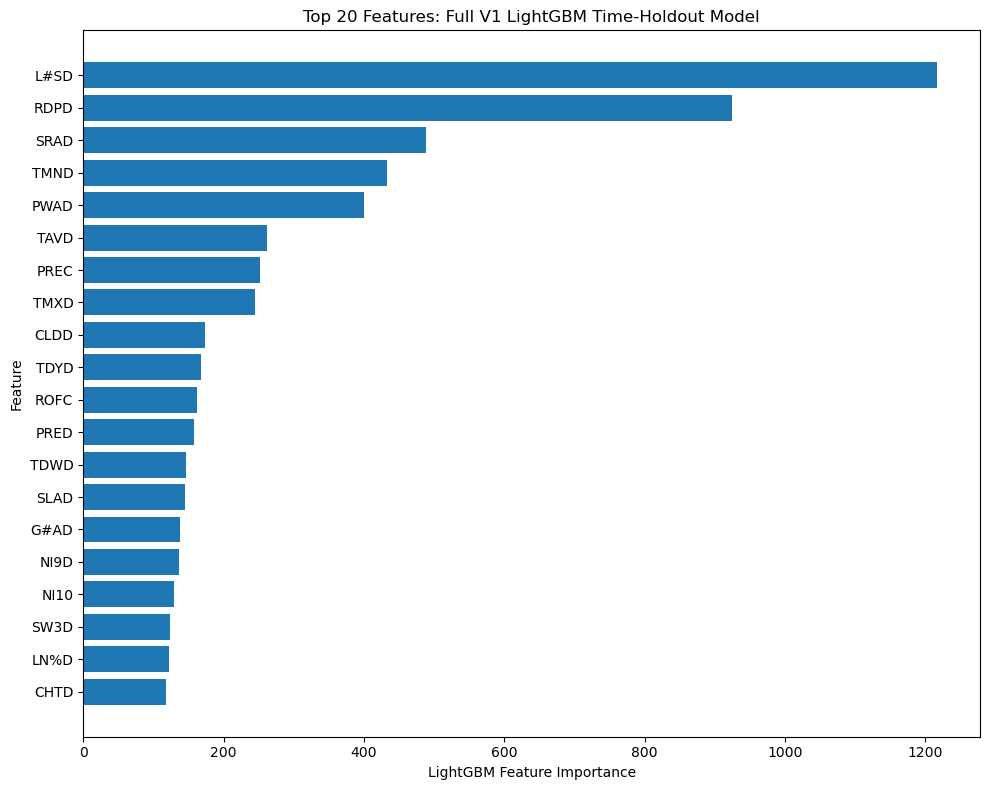

In [53]:
# Feature importance audit for the full Version 1 LightGBM time-holdout model

import pandas as pd
import matplotlib.pyplot as plt

importance_time_full_df = pd.DataFrame({
    "feature": X_train_time_full.columns,
    "importance": time_model_full.feature_importances_
}).sort_values("importance", ascending=False).reset_index(drop=True)

print("Top 30 features from Full V1 time-holdout model:")
print(importance_time_full_df.head(30))

top_n = 20
top_features_plot = importance_time_full_df.head(top_n).sort_values("importance", ascending=True)

plt.figure(figsize=(10, 8))
plt.barh(top_features_plot["feature"], top_features_plot["importance"])
plt.xlabel("LightGBM Feature Importance")
plt.ylabel("Feature")
plt.title("Top 20 Features: Full V1 LightGBM Time-Holdout Model")
plt.tight_layout()
plt.show()


## Summary of Feature Importance for the Full Time-Holdout Model

To better understand why the Full Version 1 model performed best under future-year testing at this stage, we reviewed feature importance from the LightGBM model trained on 2023–2044 and tested on 2045–2050.

The importance profile shows that the model was not relying on only one type of signal. Instead, the strongest predictors came from a combination of:

- crop-state variables,
- weather conditions,
- soil water variables,
- and nitrogen-related variables.

The top-ranked features included variables such as `L#SD`, `RDPD`, `SRAD`, `TMND`, `PWAD`, `PREC`, `NI9D`, `NI10`, and multiple soil-water variables. This showed that the model was learning from several agronomic and environmental signal groups, not only from a single shortcut feature.


In [56]:
# Clean model-choice comparison table for notebook display

import pandas as pd
from IPython.display import display

final_model_choice_clean = pd.DataFrame([
    {
        "Model Option": "LightGBM - Soil + weather only",
        "Features": X_soil_weather.shape[1],
        "Time ROC-AUC": round(time_roc, 4),
        "Time PR-AUC": round(time_pr, 4),
        "Main Strength": "Simplest and easiest to defend",
        "Main Tradeoff": "Meaningfully weaker on future-year holdout"
    },
    {
        "Model Option": "LightGBM - Reduced proxy-risk",
        "Features": X_reduced.shape[1],
        "Time ROC-AUC": round(time_roc_reduced, 4),
        "Time PR-AUC": round(time_pr_reduced, 4),
        "Main Strength": "More conservative with strong performance",
        "Main Tradeoff": "Still below Full V1 on future-year holdout"
    },
    {
        "Model Option": "LightGBM - Full V1",
        "Features": X.shape[1],
        "Time ROC-AUC": round(time_roc_full, 4),
        "Time PR-AUC": round(time_pr_full, 4),
        "Main Strength": "Best forward-in-time performance",
        "Main Tradeoff": "Uses more plant-state variables"
    },
    {
        "Model Option": "Logistic Regression - Full V1",
        "Features": X.shape[1],
        "Time ROC-AUC": round(logreg_full_roc, 4),
        "Time PR-AUC": round(logreg_full_pr, 4),
        "Main Strength": "Simple linear baseline",
        "Main Tradeoff": "Substantially weaker than LightGBM"
    }
])

display(final_model_choice_clean)


,Model Option,Features,Time ROC-AUC,Time PR-AUC,Main Strength,Main Tradeoff
0,LightGBM - Soil + weather only,84,0.9843,0.8038,Simplest and easiest to defend,Meaningfully weaker on future-year holdout
1,LightGBM - Reduced proxy-risk,108,0.9954,0.9229,More conservative with strong performance,Still below Full V1 on future-year holdout
2,LightGBM - Full V1,116,0.9993,0.9874,Best forward-in-time performance,Uses more plant-state variables
3,Logistic Regression - Full V1,116,0.9897,0.7805,Simple linear baseline,Substantially weaker than LightGBM


## Summary of Model Comparison at This Stage

We compared several model options using the most realistic robustness test run in this notebook: a **forward-in-time holdout**, where the model was trained on 2023–2044 and tested on 2045–2050.

This comparison was designed to answer two questions:

1. which model performed best under future-year generalization, and
2. whether the stronger model was meaningfully better than simpler alternatives.

### Key Findings

The **Full Version 1 LightGBM model** performed best on the forward-in-time holdout:

- **ROC-AUC:** 0.9993
- **PR-AUC:** 0.9874

For comparison:

- the **Reduced proxy-risk LightGBM** model remained strong, but lower:
  - ROC-AUC: 0.9954
  - PR-AUC: 0.9229

- the **Soil + weather only LightGBM** model was simpler, but meaningfully weaker:
  - ROC-AUC: 0.9843
  - PR-AUC: 0.8176

At this stage of the project, the Full Version 1 LightGBM model was the strongest candidate based on the forward-time comparison. This result helped guide the next modeling decisions and gave the team evidence that richer DSSAT-derived features carried useful predictive signal for the 7-day GSTD 5 alert task.
